In [1]:
import pandas as pd

import torch
from torch import nn

from aif import DataModule, Module, Trainer

In [2]:
class KaggleHousePricesDataset(DataModule):
    def __init__(self, root='../data', batch_size=64):
        super().__init__(batch_size=batch_size)

        train_path = f'{root}/house_prices_kaggle/train.csv'
        val_path = f'{root}/house_prices_kaggle/test.csv'

        self.raw_train = pd.read_csv(train_path)
        self.raw_val = pd.read_csv(val_path)

        self.train = None
        self.val = None

    def preprocess(self):
        label = 'SalePrice'
        features = pd.concat((
            self.raw_train.drop(columns=['Id', label]),
            self.raw_val.drop(columns=['Id'])
        ))

        numeric_features = features.dtypes[features.dtypes != 'str'].index
        features[numeric_features] = features[numeric_features].apply(
            lambda x: (x - x.mean()) / (x.std())
        )
        features[numeric_features] = features[numeric_features].fillna(0)

        features = pd.get_dummies(features, dummy_na=True)

        self.train = features[:self.raw_train.shape[0]].copy()
        self.train[label] = self.raw_train[label]
        self.val = features[self.raw_train.shape[0]:].copy()

    def get_dataloader(self, train):
        label = 'SalePrice'
        data = self.train if train else self.val

        if label not in data:
            return

        get_tensor = lambda x: torch.tensor(
            x.values.astype(float),
            dtype=torch.float32
        )

        tensors = (
            get_tensor(data.drop(columns=[label])),
            get_tensor(data[label]).reshape(-1, 1)
        )

        return self._get_tensorloader(tensors, train)

In [3]:
data = KaggleHousePricesDataset()

data.raw_train.shape, data.raw_val.shape

((1460, 81), (1459, 80))

In [4]:
data.preprocess()

data.train.shape, data.val.shape

((1460, 331), (1459, 330))

In [5]:
class LinearRegression(Module):
    def __init__(self, num_inputs, lr, sigma=0.01):
        super().__init__(lr)

        self.net = nn.Linear(num_inputs, 1)

        self.net.weight.data.normal_(0, sigma)
        self.net.bias.data.fill_(0)

    def forward(self, X):
        return self.net(X)

    def loss(self, y_hat, y):
        return nn.MSELoss()(y_hat, y)

    def get_w_b(self):
        return self.net.weight.detach(), self.net.bias.detach()

In [6]:
model = LinearRegression(330, 0.01)

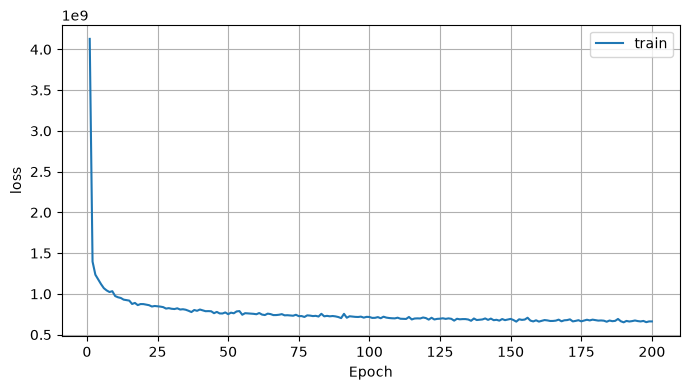

Epoch 200/200 | train_loss: 662039375.254794


In [7]:
trainer = Trainer(max_epochs=200)

trainer.fit(model, data)

In [8]:
x, y = data.train.iloc[0, :-1].copy(), data.train.iloc[0, -1].copy()
x

MSSubClass                0.06732
LotFrontage             -0.184443
LotArea                 -0.217841
OverallQual              0.646073
OverallCond             -0.507197
                           ...   
SaleCondition_Alloca        False
SaleCondition_Family        False
SaleCondition_Normal         True
SaleCondition_Partial       False
SaleCondition_nan           False
Name: 0, Length: 330, dtype: object

In [9]:
y

np.int64(208500)

In [10]:
with torch.no_grad():
    y_hat = model(torch.tensor(x.values.astype(float), dtype=torch.float32))

    print(y, y_hat.item())

208500 208226.375


In [11]:
for 

SyntaxError: invalid syntax (1235331270.py, line 1)

In [ ]:
with torch.no_grad():
    preds = []

    for _, row in data.val.iterrows():
        x = torch.tensor(row.to_numpy(dtype="float32"))
        pred = model(x)
        preds.append(pred.item())

In [ ]:
preds[0]

In [ ]:
submission_df = pd.DataFrame({
    'Id': data.raw_val.Id,
    'SalePrice': preds
})

display(submission_df)

In [ ]:
submission_df.to_csv('submission.csv', index=False)